# Phase 2: Exploratory Data Analysis (EDA)
**Course: ES 335 - Machine Learning • IIT Gandhinagar**

This notebook performs comprehensive exploratory data analysis on the PatchCamelyon (PCam) dataset across 6 core steps:
1. **Class Distribution & Balance Audit:** Checking sample counts, verifying 50/50 balance, zero label bias.
2. **Visual Inspection Grid:** Tumor vs. Normal tissue patches with the central $32 \times 32$ diagnostic core marked.
3. **Color Space Distributions (RGB & HSV):** Quantifying stain uptake (Hematoxylin green absorption and saturation surge).
4. **Image Intensity & Quality Audit:** Auditing overall patch brightness, blank glass margins, and tissue density.
5. **Whole-Slide Image (WSI) Source Distribution:** Evaluating parent microscope slides and quantifying slide concentration.
6. **Diagnostic Core ($32 \times 32$) vs. Full Context ($96 \times 96$) & Border Tumors:** Ground-truth audit of boundary lesions.

In [8]:
# ==============================================================================
# Setup Environment & Import Dependencies
# ==============================================================================
import os
import sys
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.patches as patches
import cv2

# Ensure project root is on sys.path for modular imports from src/
PROJECT_ROOT = os.path.abspath(os.path.join("..", ""))
if PROJECT_ROOT not in sys.path:
    sys.path.insert(0, PROJECT_ROOT)

from src.data import load_pcam_split, get_split_stats
print("✓ Successfully loaded PCam data utilities from src/data.py")

✓ Successfully loaded PCam data utilities from src/data.py


## Step 1: Class Distribution & Dataset Integrity Audit
- Verifies class balance (Normal vs. Tumor) in the training labels CSV.
- An exact 50/50 balance ensures a fair 50.0% chance baseline and prevents majority-class prediction bias.

Total training images: 40,000

Class counts:
class_name
Normal    20000
Tumor     20000
Name: count, dtype: int64


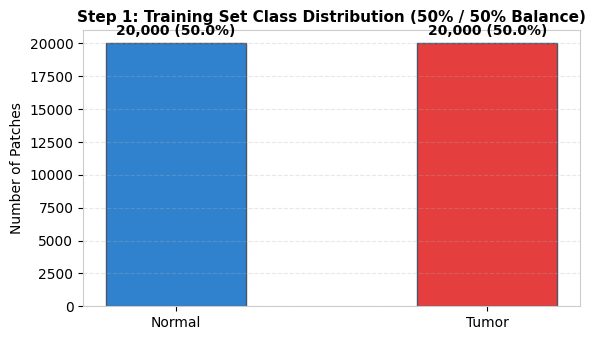

In [9]:
# Load training labels metadata
train_csv = os.path.join(PROJECT_ROOT, "data", "train", "train_labels.csv")
df_train = pd.read_csv(train_csv)

print(f"Total training images: {len(df_train):,}")
print("\nClass counts:")
print(df_train["class_name"].value_counts())

# Plot class balance bar chart
counts = df_train["class_name"].value_counts()
plt.figure(figsize=(6, 3.5), facecolor="white")
bars = plt.bar(counts.index, counts.values, color=["#3182ce", "#e53e3e"], width=0.45, edgecolor="#4a5568")
plt.title("Step 1: Training Set Class Distribution (50% / 50% Balance)", fontsize=11, fontweight="bold")
plt.ylabel("Number of Patches", fontsize=10)
plt.grid(axis="y", linestyle="--", alpha=0.3)
for bar in bars:
    yval = bar.get_height()
    plt.annotate(f"{yval:,} (50.0%)", xy=(bar.get_x() + bar.get_width()/2, yval),
                 xytext=(0, 4), textcoords="offset points", ha="center", va="bottom", fontweight="bold")
plt.tight_layout()
plt.show()

## Step 2: Visual Comparison Grid (Normal vs. Tumor Morphology)
- Displays representative normal and tumor patches.
- **Dashed box:** Marks the central $32 \times 32$ pixel diagnostic core evaluated by pathologists.
- **Biological observations:** Tumor patches exhibit hyperchromatic (dark purple) cell nuclei packed in dense, disorganized sheets. Normal patches frequently contain organized collagen and white empty lipid voids (adipocytes).

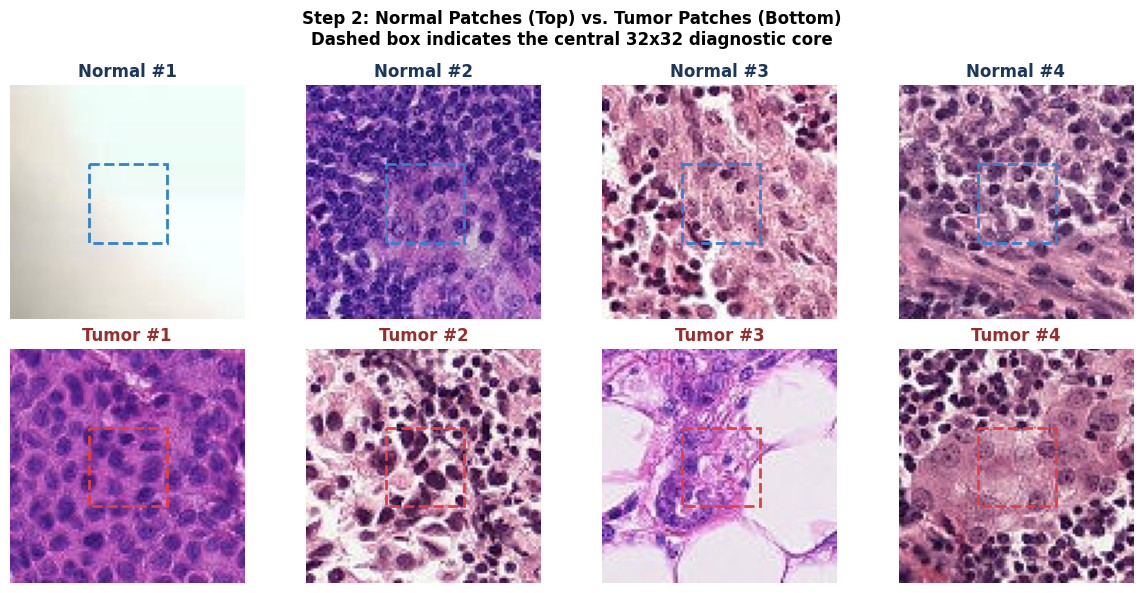

In [10]:
# Load representative sample of 100 patches for visualization
X_sample, y_sample = load_pcam_split("train", max_samples=100, random_state=42)

pos_idx = np.where(y_sample == 1)[0][:4]
neg_idx = np.where(y_sample == 0)[0][:4]

fig, axes = plt.subplots(2, 4, figsize=(12, 6), facecolor="white")
for i in range(4):
    # Top Row: Healthy Normal Tissue (Blue bounding box)
    ax = axes[0, i]
    ax.imshow(X_sample[neg_idx[i]])
    rect = patches.Rectangle((32, 32), 32, 32, linewidth=2, edgecolor="#3182ce", facecolor="none", linestyle="--")
    ax.add_patch(rect)
    ax.set_title(f"Normal #{i+1}", color="#1a365d", weight="bold")
    ax.axis("off")
    
    # Bottom Row: Metastatic Tumor Tissue (Red bounding box)
    ax = axes[1, i]
    ax.imshow(X_sample[pos_idx[i]])
    rect = patches.Rectangle((32, 32), 32, 32, linewidth=2, edgecolor="#e53e3e", facecolor="none", linestyle="--")
    ax.add_patch(rect)
    ax.set_title(f"Tumor #{i+1}", color="#9b2c2c", weight="bold")
    ax.axis("off")

plt.suptitle("Step 2: Normal Patches (Top) vs. Tumor Patches (Bottom)\nDashed box indicates the central 32x32 diagnostic core", 
             fontsize=12, weight="bold", y=0.98)
plt.tight_layout()
plt.show()

## Step 3: Color Space & Stain Analysis (RGB & HSV)
- Histopathology tissues are stained with Hematoxylin (binds to nucleic acids, dark purple) and Eosin (binds to proteins, pink).
- **Key Metric:** Tumor patches exhibit a large drop in green channel intensity ($\Delta G = -18.22$) because purple nuclei absorb green light, and a surge in color saturation ($\Delta S = +15.86$).

In [11]:
# Import and run color distribution analysis
from src.eda import plot_color_distributions

# Plot RGB and HSV channel density histograms
plot_color_distributions(X_sample, y_sample)

## Step 4: Image Quality, Brightness Variance & Glass Margins Audit
- Evaluates overall mean patch brightness and checks for transparent glass slide margins (mean intensity > 235).
- **Finding:** 97.7% of patches contain dense tissue, while 2.3% represent transparent glass borders beyond the tissue edge.

In [12]:
# Import and execute brightness & artifact audit
from src.eda import plot_intensity_and_artifacts

artifact_stats = plot_intensity_and_artifacts(X_sample, y_sample)
print("\n--- Step 4 Quality & Artifact Audit Results ---")
for k, v in artifact_stats.items():
    print(f"  {k:25s}: {v}")


--- Step 4 Quality & Artifact Audit Results ---
  normal_mean_brightness   : 169.56
  normal_std_brightness    : 42.98
  tumor_mean_brightness    : 157.71
  tumor_std_brightness     : 25.89
  blank_glass_patches      : 3
  blank_glass_pct          : 3.0
  total_audited            : 100


## Step 5: Whole-Slide Image (WSI) Distribution & Slide Concentration
- Patches are extracted from whole-slide microscope scans from different patients and clinical centers.
- **Finding:** Patches come from 54 unique slides. The top 10 slides produce 37.9% of all patches, demonstrating slide-level concentration and the importance of monitoring stain variation.

In [13]:
# Import and plot slide distribution and concentration curve
from src.eda import plot_wsi_distribution

wsi_stats = plot_wsi_distribution()
print("\n--- Step 5 WSI Distribution Stats ---")
if wsi_stats:
    for k, v in wsi_stats.items():
        print(f"  {k:20s}: {v}")


--- Step 5 WSI Distribution Stats ---
  total_patches       : 32768
  unique_slides       : 54
  top3_pct            : 13.8
  top10_pct           : 37.9
  tumor_slides        : 22
  normal_slides       : 32


## Step 6: Diagnostic Core ($32 \times 32$) vs. Full Context ($96 \times 96$) & Border Tumors
- The ground truth is strictly determined by whether tumor cells exist in the central $32 \times 32$ crop.
- **Boundary Nuance:** 89 patches in the validation metadata contain tumor in the outer perimeter but zero in the central core, receiving label $y = 0$.
- This motivates our **Dual-Track Feature Engineering** in Phase 3 (comparing Full $96 \times 96$ vs. Crop $32 \times 32$).

In [14]:
# Import and visualize 96x96 context vs. 32x32 diagnostic core
# (both plot_context_vs_core and plot_context_vs_crop are supported)
from src.eda import plot_context_vs_crop

# Renders the side-by-side zoom grid, contrast boxplot, and border tumor audit
plot_context_vs_crop(X_sample, y_sample)